In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [21]:
from scipy.stats import skew


In [22]:
bearing_df= pd.read_csv('DATA_SET\Ball Bearing and Washers.csv')
bearing_df.head()

,Sample No,Serial,M1 - NN,M2 - AM,M3 - MB,M_Avg,Avg(M_Avg),CL-X,UCL-X,LCL-X
0,Sample 1,1,10.41,10.40,10.40,10.403333,10.322,10.1256,10.432996,9.818204
1,Sample 1,2,10.38,10.41,10.40,10.396667,10.322,NaN,NaN,NaN
2,Sample 1,3,10.41,10.42,10.43,10.420000,10.322,NaN,NaN,NaN
3,Sample 1,4,10.40,10.39,10.41,10.400000,10.322,NaN,NaN,NaN
4,Sample 1,5,9.99,9.99,9.99,9.990000,10.322,NaN,NaN,NaN


In [23]:
df= bearing_df.copy()
df.head(10)

,Sample No,Serial,M1 - NN,M2 - AM,M3 - MB,M_Avg,Avg(M_Avg),CL-X,UCL-X,LCL-X
0,Sample 1,1,10.41,10.40,10.40,10.403333,10.322,10.1256,10.432996,9.818204
1,Sample 1,2,10.38,10.41,10.40,10.396667,10.322,NaN,NaN,NaN
2,Sample 1,3,10.41,10.42,10.43,10.420000,10.322,NaN,NaN,NaN
3,Sample 1,4,10.40,10.39,10.41,10.400000,10.322,NaN,NaN,NaN
4,Sample 1,5,9.99,9.99,9.99,9.990000,10.322,NaN,NaN,NaN
5,Sample 2,6,9.99,9.99,9.99,9.990000,10.243,10.1256,10.432996,9.818204
6,Sample 2,7,10.40,10.39,10.40,10.396667,10.243,NaN,NaN,NaN
7,Sample 2,8,10.40,10.41,10.42,10.410000,10.243,NaN,NaN,NaN
8,Sample 2,9,10.42,10.41,10.43,10.420000,10.243,NaN,NaN,NaN
9,Sample 2,10,10.01,9.99,9.99,9.996667,10.243,NaN,NaN,NaN


In [24]:
# rename a column
df = df.rename(columns={'M1 - NN': 'Neelotpal'})
df = df.rename(columns={'M2 - AM': 'Anush'})
df = df.rename(columns={'M3 - MB': 'Mayukh'})
df = df.rename(columns={'M_Avg': 'Average_Reading'})
df = df.rename(columns={'Avg(M_Avg)': 'Average'})
df



,Sample No,Serial,Neelotpal,Anush,Mayukh,Average_Reading,Average,CL-X,UCL-X,LCL-X
0,Sample 1,1,10.410,10.400,10.400,10.403333,10.322,10.1256,10.432996,9.818204
1,Sample 1,2,10.380,10.410,10.400,10.396667,10.322,NaN,NaN,NaN
2,Sample 1,3,10.410,10.420,10.430,10.420000,10.322,NaN,NaN,NaN
3,Sample 1,4,10.400,10.390,10.410,10.400000,10.322,NaN,NaN,NaN
4,Sample 1,5,9.990,9.990,9.990,9.990000,10.322,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
95,Sample 20,96,10.413,10.409,10.404,10.408667,10.067,10.1256,10.432996,9.818204
96,Sample 20,97,9.992,9.989,9.993,9.991333,10.067,NaN,NaN,NaN
97,Sample 20,98,9.990,9.994,9.994,9.992667,10.067,NaN,NaN,NaN
98,Sample 20,99,10.413,10.408,10.407,10.409333,10.067,NaN,NaN,NaN


In [25]:
df[["Sample No", "CL-X", "UCL-X", "LCL-X"]]

df[df["CL-X"].notna()]
# make a dictinary of the above dataframe with Sample No as key and CL-X, UCL-X, LCL-X as values in a list
data_dict = df[df["CL-X"].notna()].set_index("Sample No")[["CL-X", "UCL-X", "LCL-X"]].to_dict("index")
data_dict

{'Sample 1': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 2': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 3': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 4': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 5': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 6': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 7': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 8': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 9': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 10': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 11': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 12': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample 13': {'CL-X': 10.1256, 'UCL-X': 10.43299565, 'LCL-X': 9.818204352},
 'Sample

In [26]:
for index, row in df.iterrows():
    if pd.isna(row["CL-X"]):
        sample_no = row["Sample No"]
        df.at[index, "CL-X"] = data_dict[sample_no]["CL-X"]
        df.at[index, "UCL-X"] = data_dict[sample_no]["UCL-X"]
        df.at[index, "LCL-X"] = data_dict[sample_no]["LCL-X"]


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Sample No        100 non-null    str    
 1   Serial           100 non-null    int64  
 2   Neelotpal        100 non-null    float64
 3   Anush            100 non-null    float64
 4   Mayukh           100 non-null    float64
 5   Average_Reading  100 non-null    float64
 6   Average          100 non-null    float64
 7   CL-X             100 non-null    float64
 8   UCL-X            100 non-null    float64
 9   LCL-X            100 non-null    float64
dtypes: float64(8), int64(1), str(1)
memory usage: 7.9 KB


In [28]:
df.shape

(100, 10)

In [29]:
df_2= df.groupby("Sample No")["Average"].mean()

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Sample 1'),
  Text(1, 0, 'Sample 10'),
  Text(2, 0, 'Sample 11'),
  Text(3, 0, 'Sample 12'),
  Text(4, 0, 'Sample 13'),
  Text(5, 0, 'Sample 14'),
  Text(6, 0, 'Sample 15'),
  Text(7, 0, 'Sample 16'),
  Text(8, 0, 'Sample 17'),
  Text(9, 0, 'Sample 18'),
  Text(10, 0, 'Sample 19'),
  Text(11, 0, 'Sample 2'),
  Text(12, 0, 'Sample 20'),
  Text(13, 0, 'Sample 3'),
  Text(14, 0, 'Sample 4'),
  Text(15, 0, 'Sample 5'),
  Text(16, 0, 'Sample 6'),
  Text(17, 0, 'Sample 7'),
  Text(18, 0, 'Sample 8'),
  Text(19, 0, 'Sample 9')])

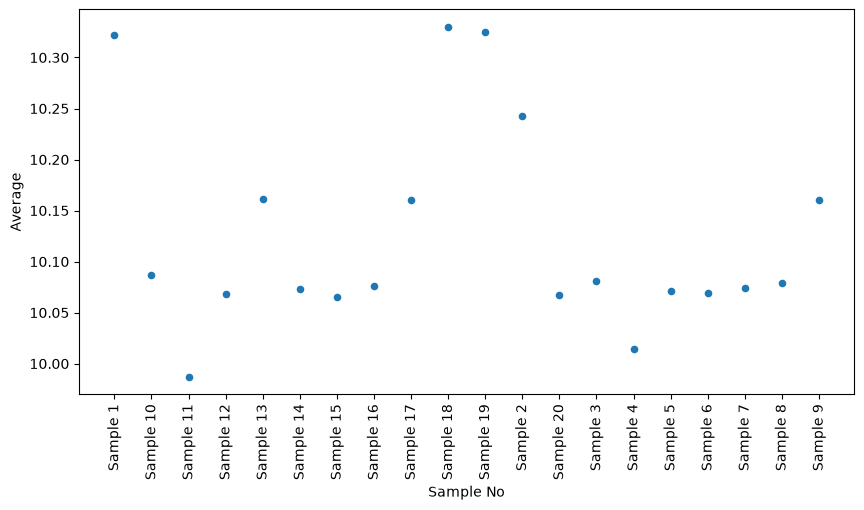

In [30]:
df_2.reset_index().plot(kind='scatter', x='Sample No', y='Average', figsize=(10, 5))
plt.xticks(rotation=90)

In [31]:
df["Average"].describe()

count    100.000000
mean      10.125600
std        0.100335
min        9.987000
25%       10.068750
50%       10.077500
75%       10.160250
max       10.330000
Name: Average, dtype: float64

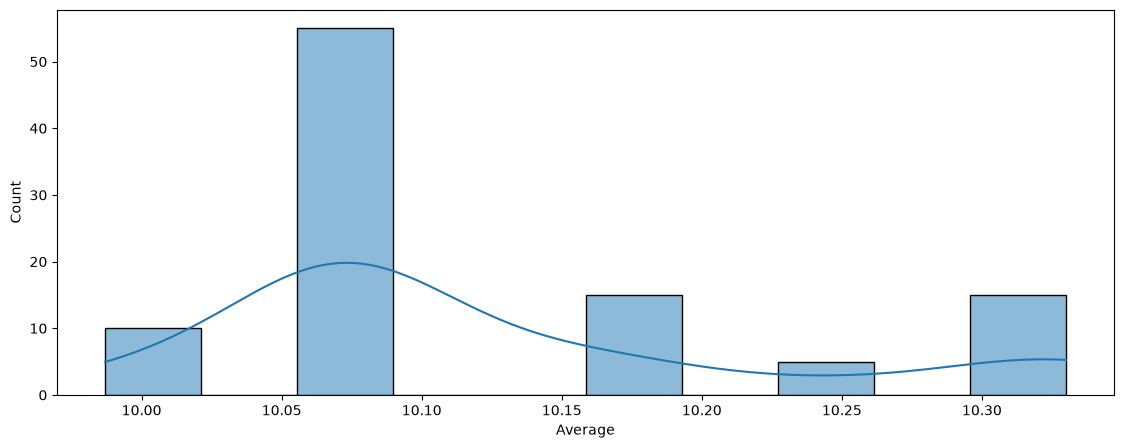

In [32]:
# plot hist plot of both Average column along with its kde, in different graphs


plt.figure(figsize=(30, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df, x='Average', kde=True, alpha=0.5, bins=10)



plt.show()


<Axes: ylabel='Average'>

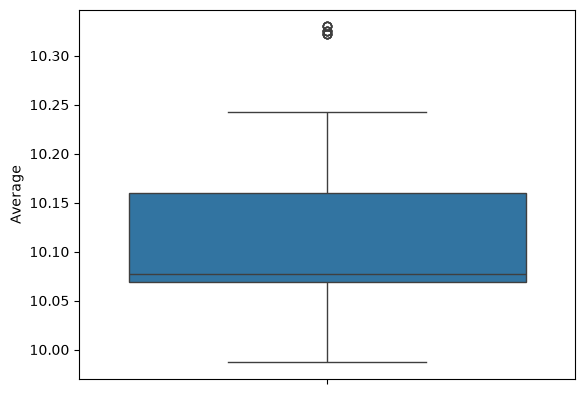

In [33]:
# box plot of Average 
sns.boxplot(data=df, y='Average')

In [34]:
# detect the outlier rows
Q1 = df['Average'].quantile(0.25)
Q3 = df['Average'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_rows = df[(df['Average'] < lower_bound) | (df['Average'] > upper_bound)]
outlier_rows

,Sample No,Serial,Neelotpal,Anush,Mayukh,Average_Reading,Average,CL-X,UCL-X,LCL-X
0,Sample 1,1,10.410,10.400,10.400,10.403333,10.322,10.1256,10.432996,9.818204
1,Sample 1,2,10.380,10.410,10.400,10.396667,10.322,10.1256,10.432996,9.818204
2,Sample 1,3,10.410,10.420,10.430,10.420000,10.322,10.1256,10.432996,9.818204
3,Sample 1,4,10.400,10.390,10.410,10.400000,10.322,10.1256,10.432996,9.818204
4,Sample 1,5,9.990,9.990,9.990,9.990000,10.322,10.1256,10.432996,9.818204
85,Sample 18,86,10.409,10.398,10.404,10.403667,10.330,10.1256,10.432996,9.818204
86,Sample 18,87,10.432,10.429,10.420,10.427000,10.330,10.1256,10.432996,9.818204
87,Sample 18,88,10.449,10.431,10.412,10.430667,10.330,10.1256,10.432996,9.818204
88,Sample 18,89,9.996,9.995,9.996,9.995667,10.330,10.1256,10.432996,9.818204
89,Sample 18,90,10.396,10.397,10.393,10.395333,10.330,10.1256,10.432996,9.818204


In [35]:
# finding skewness of Average column
skewness = skew(df["Average"])
print(f"Skewness of Average column: {skewness}")

Skewness of Average column: 1.0112740721448732


In [36]:
# finding kurtosis of Average column
kurtosis = df["Average"].kurtosis()
print(f"Kurtosis of Average column: {kurtosis}")

Kurtosis of Average column: -0.11749470119282579


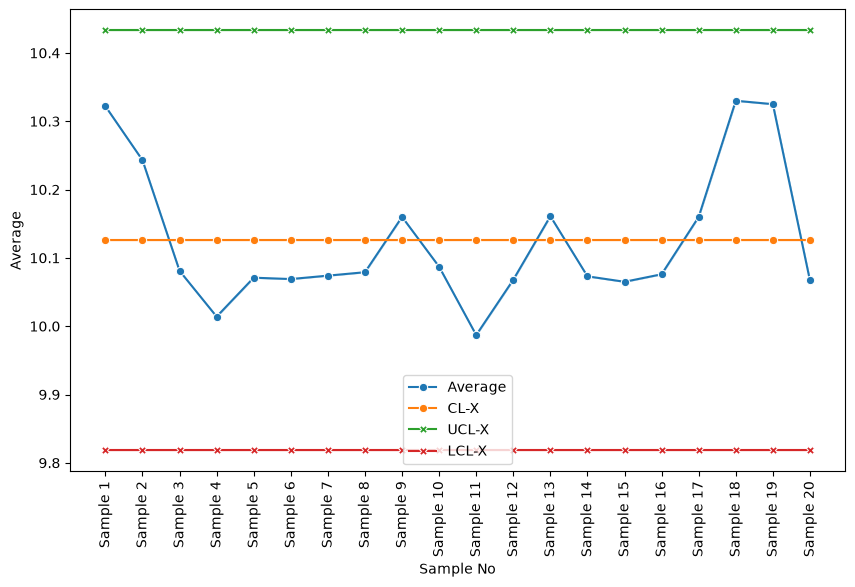

In [37]:
# Plot the control charts
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Sample No', y='Average', marker='o', label='Average')
sns.lineplot(data=df, x='Sample No', y='CL-X', marker='o', label='CL-X')
sns.lineplot(data=df, x='Sample No', y='UCL-X', marker='X', label='UCL-X')
sns.lineplot(data=df, x='Sample No', y='LCL-X', marker='X', label='LCL-X')
plt.xticks(rotation=90)
plt.show()

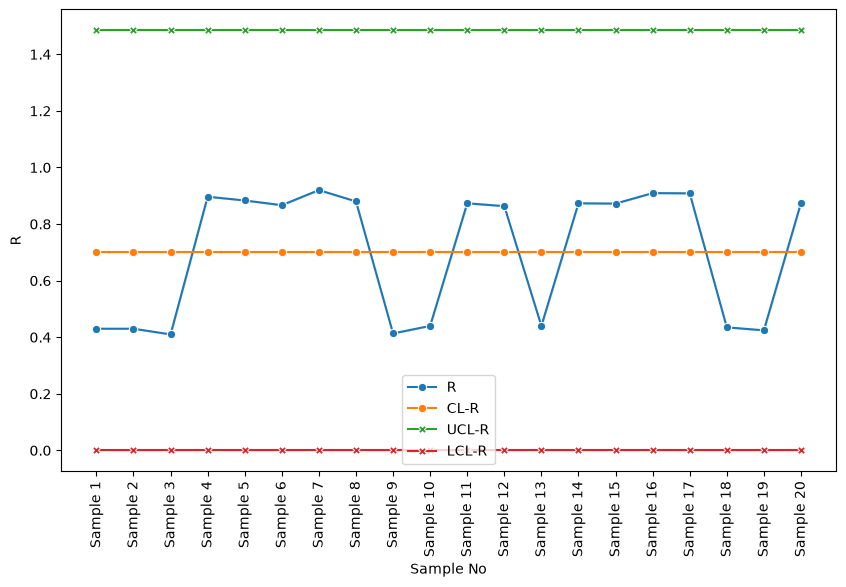

In [38]:
# also draw R chart for the same data, with R, CL-R, UCL-R, LCL-R columns.
plt.figure(figsize=(10, 6))
# Calculate the range for each sample subgroup
df["R"] = df.groupby("Sample No")["Average_Reading"].transform(
    lambda values: values.max() - values.min()
)

# R-chart control limits for subgroup size n=5
CL_R = df.groupby("Sample No")["R"].first().mean()
D3, D4 = 0, 2.114

df["CL-R"] = CL_R
df["UCL-R"] = D4 * CL_R
df["LCL-R"] = D3 * CL_R

sns.lineplot(data=df, x="Sample No", y="R", marker="o", label="R")
sns.lineplot(data=df, x='Sample No', y='CL-R', marker='o', label='CL-R')
sns.lineplot(data=df, x='Sample No', y='UCL-R', marker='X', label='UCL-R')
sns.lineplot(data=df, x='Sample No', y='LCL-R', marker='X', label='LCL-R')
plt.xticks(rotation=90)
plt.show()